# Bases del residuo bajo entrenamiento puramente físico

Se comparan POD sin centrar, PCA centrada y PCA + media con igual dimensión total por semilla e intervalo, QR directo y reconstrucción del lote hasta 128 con el mismo prefijo Sobol. La media ocupa una dirección dentro del presupuesto. Se conserva la pérdida solo PDE, transformación IC/BC, red 3×32, Adam, candidatos fijos y veinte snapshots cada cinco pasos del último intervalo de cien.

El calendario de dimensiones se extrae de la trayectoria PCA + media al 95 % del notebook 26, antes de ejecutar los nuevos brazos. POD y PCA centrada usan ese calendario, no eligen su propio rango ni umbral. Es un control condicional emparejado para comparar subespacios a igual presupuesto; no evalúa sus versiones adaptativas autónomas. PCA + media y Sobol se reutilizan. La dimensión total incluye la media independiente en la referencia.

POD toma los primeros d modos de R; PCA toma los primeros d componentes de R centrada por punto. Se construyen bases ortonormales antes del mismo QR. El selector falla explícitamente si no alcanza el rango numérico solicitado, sin añadir direcciones artificiales. Las historias iniciales son comunes; después evolucionan con cada red. Las coordenadas y el complemento Sobol permanecen emparejados.

Diez semillas 2071–2080, cien pasos uniformes y diez mil de continuación. Son semillas ya estudiadas: control exploratorio, no confirmación independiente. No hay datos supervisados en el objetivo, poda ni ampliación log-det.

| Base/control | RMSE prueba ± DE | Residuo RMS |
|---|---:|---:|
| POD sin centrar | 0.11846 ± 0.05689 | 0.30533 |
| PCA centrada | 0.10543 ± 0.04106 | 0.31332 |
| PCA + media | 0.13782 ± 0.06816 | 0.28619 |
| Sobol | 0.25193 ± 0.11611 | 0.82013 |


PCA + media frente a POD sin centrar: diferencia media RMSE +0.01936; mejora en 4/10 semillas; bootstrap pareado 95 % [-0.01108, +0.05312].

PCA centrada frente a POD sin centrar: diferencia media RMSE -0.01303; mejora en 4/10 semillas; bootstrap pareado 95 % [-0.06210, +0.03336].

PCA + media frente a PCA centrada: diferencia media RMSE +0.03239; mejora en 4/10 semillas; bootstrap pareado 95 % [-0.02134, +0.08992].

POD sin centrar frente a Sobol: diferencia media RMSE -0.13348; mejora en 9/10 semillas; bootstrap pareado 95 % [-0.18466, -0.07899].

PCA centrada frente a Sobol: diferencia media RMSE -0.14651; mejora en 8/10 semillas; bootstrap pareado 95 % [-0.22503, -0.06934].

PCA + media frente a Sobol: diferencia media RMSE -0.11412; mejora en 7/10 semillas; bootstrap pareado 95 % [-0.18472, -0.04187].

**Comparación**

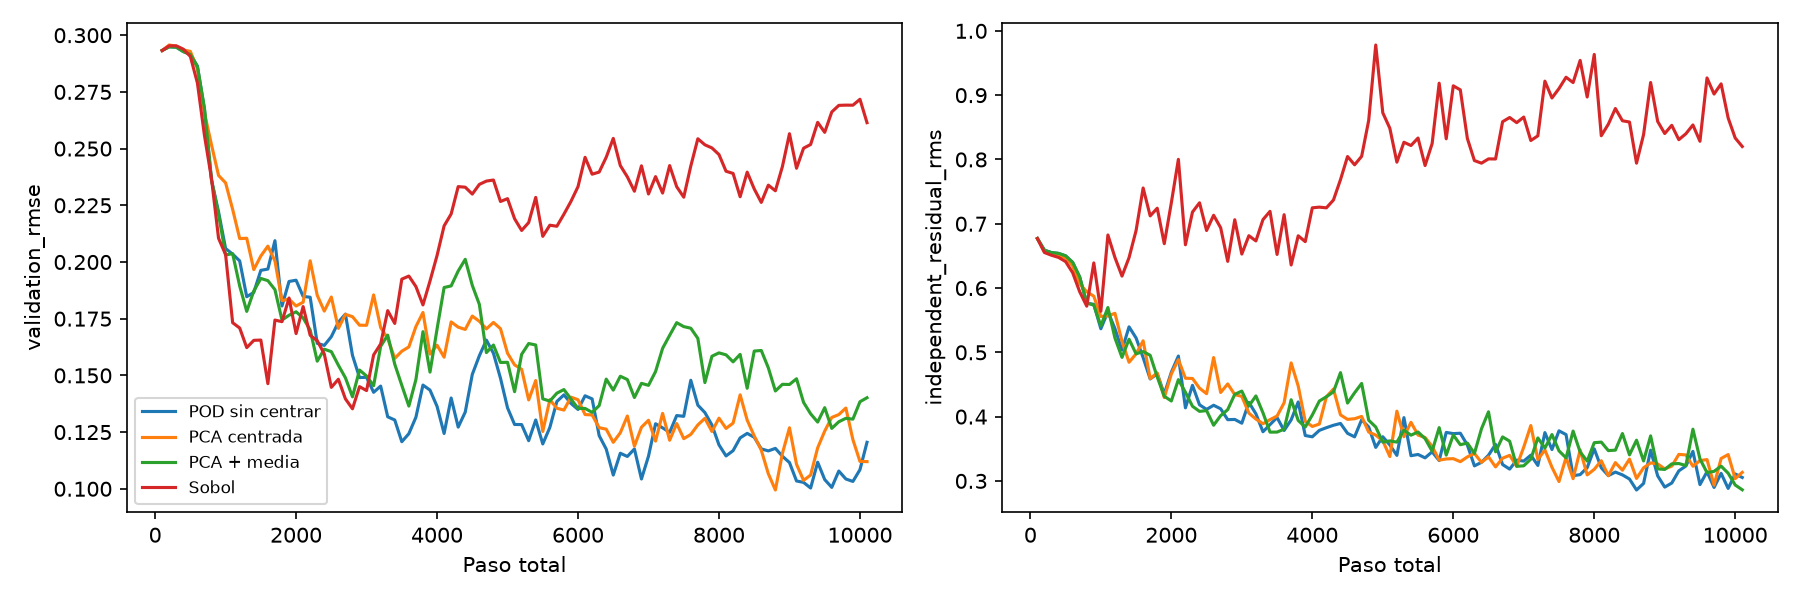

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/pde_bases/matched_pde_bases_10seeds_10k_v1/comparison.png'), format='png', embed=True))


Se evalúa el modelo terminal en prueba reservada sin ajustar parámetros a prueba. DE describe dispersión entre semillas. El bootstrap con diez diferencias es exploratorio y no corrige multiplicidad. El menor residuo no garantiza menor error de solución. Las fracciones de energía, fluctuaciones y media capturadas se guardan para los brazos nuevos; las referencias reutilizadas no incluyen esas columnas, que se dejan vacías.

Las auditorías reconstruyen cien selecciones QR y comprueban calendario de rangos, tamaño activo, complemento Sobol e inicio común. Las restricciones IC/BC se verifican por el mismo mecanismo del notebook 26. manifest.json identifica cada procedencia.

Reproducir: `python scripts/run_collocation_pde_bases.py`. Configuración en pca_collocation/configs/burgers_pde_bases.json. Corridas completas se reutilizan. Las figuras están incrustadas como PNG.